<a href="https://colab.research.google.com/github/sanoop070/nasa-exoplanet-finder/blob/main/exoplanet_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================
# NASA EXOPLANET FINDER
# Project: Exoplanet Transit Detection using 1D CNN
# Data Source: NASA Kepler Mission
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import lightkurve as lk

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("All libraries imported successfully!")
print("Lightkurve version:", lk.__version__)
print("PyTorch version:", torch.__version__)

All libraries imported successfully!
Lightkurve version: 2.6.0
PyTorch version: 2.14.1+cpu


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [ ]:
!pip install lightkurve

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 41.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 48.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 54.8 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=c90d69e91f8607ce8e1fc4446cbaf4d071a7c78ad5db416e4cc7b7a1e20d1a2a
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=3df3940de5159832b3e5808d53e1c3e09377b8a0f6bd53037493ade921b9d880
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a897019

## 02. NASA Kepler Data Collection


In [4]:

# ============================================
# NASA KEPLER DATA COLLECTION
# ============================================

# Search NASA archive for Kepler-10 observations

search_result = lk.search_lightcurve(
    "Kepler-10",
    mission="Kepler"
)

print("Total data products found:", len(search_result))
print(search_result)


Total data products found: 50
SearchResult containing 50 data products.

 #       mission      year   author   exptime         target_name          distance
                                         s                                  arcsec 
--- ----------------- ---- ---------- ------- ---------------------------- --------
  0 Kepler Quarter 02 2009     Kepler      60                kplr011904151      0.0
  1 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  2 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  3 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  4 Kepler Quarter 00 2009     Kepler    1800                kplr011904151      0.0
  5 Kepler Quarter 01 2009     Kepler    1800                kplr011904151      0.0
  6 Kepler Quarter 02 2009     Kepler    1800                kplr011904151      0.0
  7 Kepler Quarter 03 2009     Kepler    1800                kplr011904151      0.0
  8

In [5]:

# ============================================
# 03. FILTER KEPLER LONG-CADENCE DATA
# ============================================

exposure_seconds = np.asarray(
    search_result.table["exptime"],
    dtype=float
)

authors = np.asarray(
    search_result.table["author"]
)

mask = (
    (exposure_seconds == 1800) &
    (authors == "Kepler")
)

long_cadence = search_result[mask]

print("Kepler long-cadence observations:", len(long_cadence))
print(long_cadence)



Kepler long-cadence observations: 15
SearchResult containing 15 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr011904151      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr011904151      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr011904151      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr011904151      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr011904151      0.0
  5 Kepler Quarter 05 2010 Kepler    1800 kplr011904151      0.0
  6 Kepler Quarter 06 2010 Kepler    1800 kplr011904151      0.0
  7 Kepler Quarter 07 2010 Kepler    1800 kplr011904151      0.0
  8 Kepler Quarter 09 2011 Kepler    1800 kplr011904151      0.0
  9 Kepler Quarter 10 2011 Kepler    1800 kplr011904151      0.0
 10 Kepler Quarter 11 2012 Kepler    1800 kplr011904151      0.0
 11 Kepler

In [6]:

# ============================================
# 04. DOWNLOAD KEPLER OBSERVATION
# ============================================

lc = long_cadence[0].download()

print("Download successful!")
print(lc)
print("Data points:", len(lc))


Download successful!
       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 120.5391465105713  5.0146684e+05 ...  1.7792054e-03  3.3286733e-03
120.55958073025249  5.0141212e+05 ...  1.9566093e-03  3.5631030e-03
120.58001484981651  5.0140281e+05 ...  2.0698714e-03  3.4072644e-03
120.60044916937477  5.0135972e+05 ...  2.4259784e-03  3.0491522e-03
120.62088338893955  5.0144759e+05 ...  2.7262936e-03  3.2327282e-03
120.64131750838715  5.0142422e+05 ...  2.8024365e-03  2.5497559e-03
120.66175172782823  5.0134612e+05 ...  2.9968296e-03  2.9109719e-03
120.68218604727736  5.0136928e+05 ...  2.9321318e-03  2.7981971e-03
120.70262016672496  5.0140212e+05 ...  2.9108874e-03  2.8240951e-03
               ...            ... ...            ...            ...
130.06148738515185  5.0152938e+05 ... -4.6389936e-03 -7.1408441e-03
130.08192158433667  5.01570

In [7]:

# ============================================
# 04. DOWNLOAD KEPLER OBSERVATION
# ============================================

# Download Quarter 00
lc = long_cadence[0].download()

print("Download successful!")
print(lc)

print("Total data points:", len(lc))


Download successful!
       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 120.5391465105713  5.0146684e+05 ...  1.7792054e-03  3.3286733e-03
120.55958073025249  5.0141212e+05 ...  1.9566093e-03  3.5631030e-03
120.58001484981651  5.0140281e+05 ...  2.0698714e-03  3.4072644e-03
120.60044916937477  5.0135972e+05 ...  2.4259784e-03  3.0491522e-03
120.62088338893955  5.0144759e+05 ...  2.7262936e-03  3.2327282e-03
120.64131750838715  5.0142422e+05 ...  2.8024365e-03  2.5497559e-03
120.66175172782823  5.0134612e+05 ...  2.9968296e-03  2.9109719e-03
120.68218604727736  5.0136928e+05 ...  2.9321318e-03  2.7981971e-03
120.70262016672496  5.0140212e+05 ...  2.9108874e-03  2.8240951e-03
               ...            ... ...            ...            ...
130.06148738515185  5.0152938e+05 ... -4.6389936e-03 -7.1408441e-03
130.08192158433667  5.01570

<Figure size 1200x500 with 0 Axes>

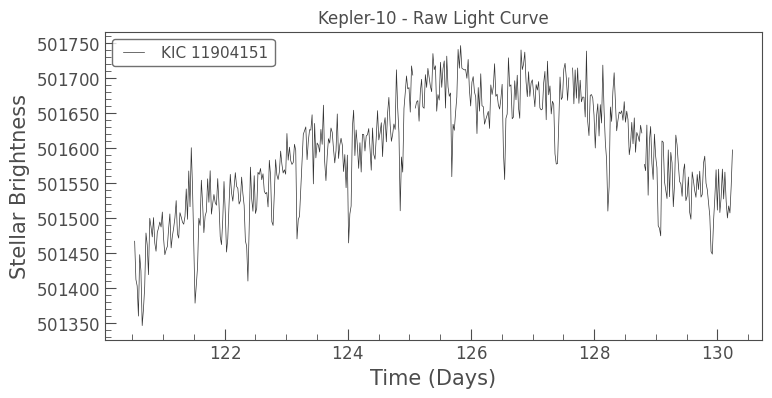

In [8]:

# ============================================
# 05. RAW LIGHT CURVE VISUALIZATION
# ============================================

plt.figure(figsize=(12, 5))

lc.plot()

plt.title("Kepler-10 - Raw Light Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Stellar Brightness")

plt.show()


In [9]:

# ============================================
# DATA CLEANING
# ============================================

# Remove missing values
lc_clean = lc.remove_nans()

# Remove statistical outliers
lc_clean = lc_clean.remove_outliers()

print("Original data points:", len(lc))
print("Cleaned data points:", len(lc_clean))

# Normalize stellar brightness
lc_normalized = lc_clean.normalize()

print("Normalization completed!")
print(lc_normalized)


Original data points: 473
Cleaned data points: 469
Normalization completed!
       time             flux      ...   pos_corr1      pos_corr2   
                                  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 120.5391465105713  9.9973410e-01 ...  1.7792054e-03  3.3286733e-03
120.55958073025249  9.9962503e-01 ...  1.9566093e-03  3.5631030e-03
120.58001484981651  9.9960643e-01 ...  2.0698714e-03  3.4072644e-03
120.60044916937477  9.9952054e-01 ...  2.4259784e-03  3.0491522e-03
120.62088338893955  9.9969572e-01 ...  2.7262936e-03  3.2327282e-03
120.64131750838715  9.9964911e-01 ...  2.8024365e-03  2.5497559e-03
120.66175172782823  9.9949342e-01 ...  2.9968296e-03  2.9109719e-03
120.68218604727736  9.9953961e-01 ...  2.9321318e-03  2.7981971e-03
120.70262016672496  9.9960506e-01 ...  2.9108874e-03  2.8240951e-03
               ...            ... ...            ...            ...
130.06148738515185  9.9985874e-01 ... -4

<Figure size 1200x500 with 0 Axes>

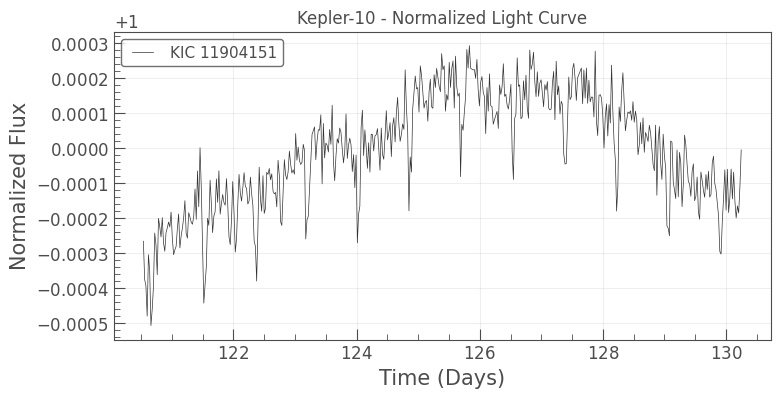

In [10]:

# ============================================
# NORMALIZED LIGHT CURVE
# ============================================

plt.figure(figsize=(12, 5))

lc_normalized.plot()

plt.title("Kepler-10 - Normalized Light Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.2)
plt.show()


In [11]:

# ============================================
# DETRENDING THE LIGHT CURVE
# ============================================

lc_flat = lc_normalized.flatten(
    window_length=101,
    polyorder=2
)

print("Detrending completed!")
print("Original data points:", len(lc_normalized))
print("Detrended data points:", len(lc_flat))


Detrending completed!
Original data points: 469
Detrended data points: 469


<Figure size 1400x500 with 0 Axes>

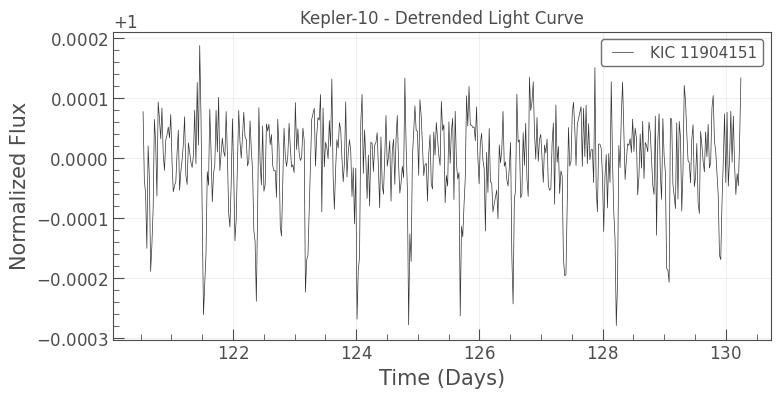

In [12]:

# ============================================
# DETRENDED LIGHT CURVE
# ============================================

plt.figure(figsize=(14, 5))

lc_flat.plot()

plt.title("Kepler-10 - Detrended Light Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.2)
plt.show()


In [13]:

# ============================================
# BOX LEAST SQUARES - TRANSIT SEARCH
# ============================================

from astropy.timeseries import BoxLeastSquares

# Extract time and flux
time = lc_flat.time.value
flux = lc_flat.flux.value

# Remove invalid values
valid = np.isfinite(time) & np.isfinite(flux)

time = time[valid]
flux = flux[valid]

# Create BLS model
bls_model = BoxLeastSquares(time, flux)

# Search orbital periods from 0.5 to 2 days
periods = np.arange(0.5, 2.0, 0.0005)

# Test transit durations (days)
durations = np.arange(0.5, 4.0, 0.5) / 24

# Perform period search
bls_result = bls_model.power(
    periods,
    durations
)

# Find strongest signal
best_index = np.argmax(bls_result.power)

best_period = bls_result.period[best_index]
best_duration = bls_result.duration[best_index]
best_depth = bls_result.depth[best_index]

print("BLS search completed!")
print("Best candidate period:", best_period, "days")
print("Transit duration:", best_duration * 24, "hours")
print("Transit depth:", best_depth)


BLS search completed!
Best candidate period: 0.8394999999999626 days
Transit duration: 1.5 hours
Transit depth: 0.00018471477392245327


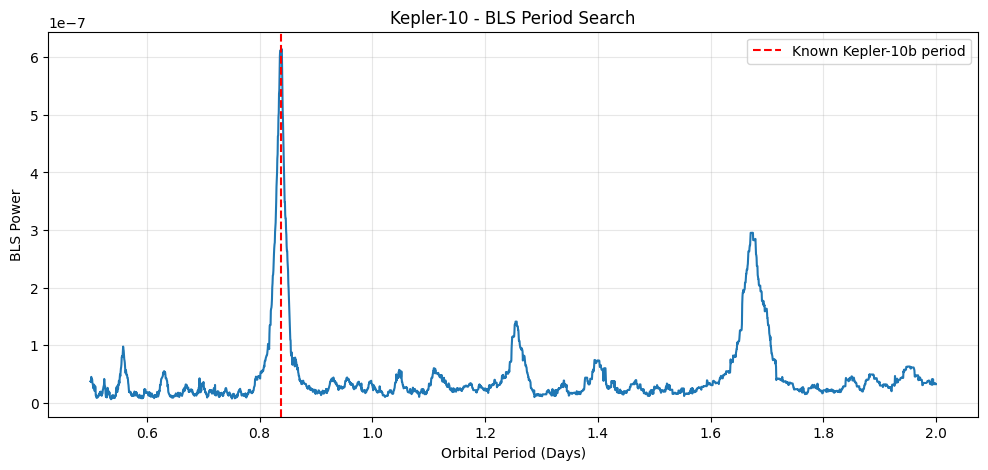

In [14]:

# ============================================
# BLS PERIODOGRAM
# ============================================

plt.figure(figsize=(12, 5))

plt.plot(
    bls_result.period,
    bls_result.power
)

plt.axvline(
    0.8375,
    color="red",
    linestyle="--",
    label="Known Kepler-10b period"
)

plt.title("Kepler-10 - BLS Period Search")
plt.xlabel("Orbital Period (Days)")
plt.ylabel("BLS Power")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


Phase folding completed!
Orbital period: 0.8394999999999626 days


<Figure size 1200x500 with 0 Axes>

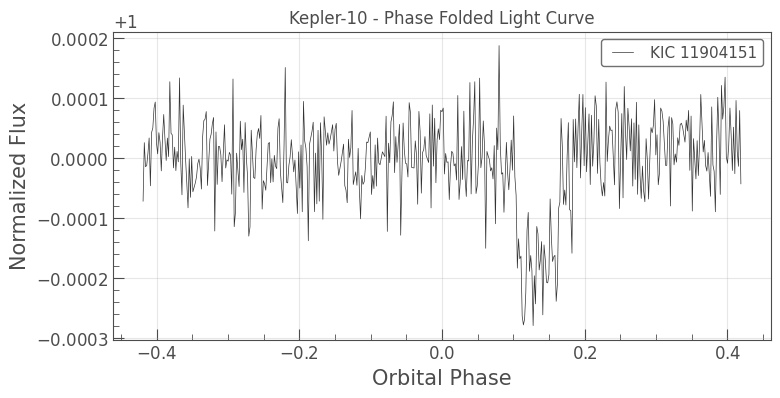

In [15]:

# ============================================
# PHASE FOLDING
# ============================================

folded_lc = lc_flat.fold(
    period=best_period
)

print("Phase folding completed!")
print("Orbital period:", best_period, "days")

# Plot phase-folded light curve
plt.figure(figsize=(12, 5))

folded_lc.plot()

plt.title("Kepler-10 - Phase Folded Light Curve")
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.3)
plt.show()


10. Transit Alignment


Orbital period: 0.8394999999999626
Estimated transit midpoint: 120.67456317723797


<Figure size 1200x500 with 0 Axes>

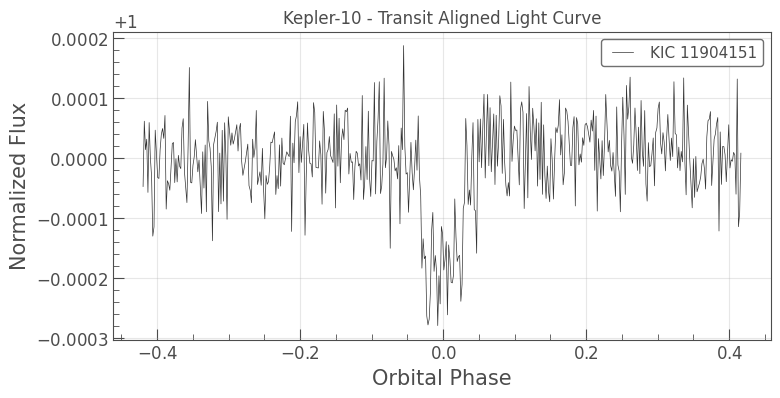

In [16]:

# ============================================
# TRANSIT ALIGNMENT
# ============================================

# Find strongest BLS signal
best_index = np.argmax(bls_result.power)

# Get estimated transit midpoint
best_transit_time = bls_result.transit_time[best_index]

print("Orbital period:", best_period)
print("Estimated transit midpoint:", best_transit_time)

# Fold around the estimated transit midpoint
folded_aligned = lc_flat.fold(
    period=best_period,
    epoch_time=best_transit_time
)

# Plot aligned light curve
plt.figure(figsize=(12, 5))

folded_aligned.plot()

plt.title("Kepler-10 - Transit Aligned Light Curve")
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.3)
plt.show()


11. Refining the Orbital Period

In [18]:

# ============================================
# REFINED BLS PERIOD SEARCH
# ============================================

# Search more precisely around our candidate
refined_periods = np.linspace(
    0.82, 0.86, 2001
)

refined_result = bls_model.power(
    refined_periods,
    durations
)

# Find refined best period
refined_index = np.argmax(refined_result.power)

refined_period = refined_result.period[refined_index]

print("Original period:", best_period)
print("Refined period:", refined_period, "days")

print(
    "Known Kepler-10b period:",
    0.8375,
    "days"
)


Original period: 0.8394999999999626
Refined period: 0.8391 days
Known Kepler-10b period: 0.8375 days
